In [4]:
import pandas as pd 
import seaborn as sns
import kagglehub
import numpy as np
from bootcampviztools import (
    plot_combined_graphs,
    pinta_distribucion_categoricas,
    plot_categorical_relationship_fin,
    plot_grouped_boxplots,
    plot_grouped_histograms,
    grafico_dispersion_con_correlacion,
    plot_categorical_numerical_relationship
)
from scipy.stats import pearsonr

In [12]:

path = kagglehub.dataset_download(
    "amitanshjoshi/spotify-1million-tracks"
)

npath=path+'/spotify_data.csv'
archivo=pd.read_csv(npath, sep=',',index_col=0)
archivo.columns
archivo=archivo[[
        'artist_name', 'track_name', 'track_id', 'popularity', 'genre','year',
        'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
        'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
        'duration_ms', 'time_signature']]
archivo

,artist_name,track_name,track_id,popularity,genre,year,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
0,Jason Mraz,I Won't Give Up,53QF56cjZA9RTuuMZDrSA6,68,acoustic,2012,0.483,0.303,4,-10.058,1,0.0429,0.6940,0.000000,0.1150,0.1390,133.406,240166,3
1,Jason Mraz,93 Million Miles,1s8tP3jP4GZcyHDsjvw218,50,acoustic,2012,0.572,0.454,3,-10.286,1,0.0258,0.4770,0.000014,0.0974,0.5150,140.182,216387,4
2,Joshua Hyslop,Do Not Let Me Go,7BRCa8MPiyuvr2VU3O9W0F,57,acoustic,2012,0.409,0.234,3,-13.711,1,0.0323,0.3380,0.000050,0.0895,0.1450,139.832,158960,4
3,Boyce Avenue,Fast Car,63wsZUhUZLlh1OsyrZq7sz,58,acoustic,2012,0.392,0.251,10,-9.845,1,0.0363,0.8070,0.000000,0.0797,0.5080,204.961,304293,4
4,Andrew Belle,Sky's Still Blue,6nXIYClvJAfi6ujLiKqEq8,54,acoustic,2012,0.430,0.791,6,-5.419,0,0.0302,0.0726,0.019300,0.1100,0.2170,171.864,244320,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1473391,Nicola Conte,Black Spirits,0m27F0IGHLGAWhqd6ccYst,4,trip-hop,2011,0.373,0.742,10,-6.453,0,0.0736,0.3250,0.000141,0.1590,0.5220,107.951,344013,3
1473392,Nicola Conte,Quiet Dawn,6er9p611eHEcUCU50j7D57,3,trip-hop,2011,0.516,0.675,7,-7.588,0,0.0326,0.7880,0.000129,0.1300,0.2640,119.897,285067,4
1473393,Amon Tobin,Morning Ms Candis,7jsMMqxy1tt0rH5FzYcZTQ,2,trip-hop,2011,0.491,0.440,5,-8.512,1,0.0274,0.4770,0.003130,0.0936,0.0351,100.076,214253,4
1473394,Peace Orchestra,Happy Christmas (War Is Over),77lA1InUaXztuRk2vOzD1S,0,trip-hop,2011,0.480,0.405,0,-13.343,1,0.0276,0.4310,0.000063,0.1250,0.2020,133.885,239133,3


In [7]:
df1 = archivo.groupby('year', as_index=False).median(numeric_only=True)
df1=df1.drop(columns=['key','time_signature','mode'])
df1


,year,popularity,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,2000,6.0,0.542,0.647,-8.5965,0.0477,0.2210,0.001480,0.135,0.518,118.6615,233933.0
1,2001,7.0,0.540,0.641,-8.4450,0.0477,0.2220,0.001550,0.135,0.488,117.9920,234400.0
2,2002,8.0,0.548,0.666,-8.0930,0.0486,0.1850,0.001490,0.137,0.504,119.0930,236566.5
3,2003,8.0,0.539,0.677,-7.9335,0.0487,0.1820,0.001460,0.137,0.492,119.8215,233667.0
4,2004,8.0,0.540,0.687,-7.6820,0.0492,0.1810,0.000961,0.139,0.491,119.9740,235036.0
5,2005,10.0,0.538,0.682,-7.8290,0.0494,0.1690,0.001350,0.139,0.485,120.0730,234381.0
6,2006,9.0,0.544,0.683,-7.7390,0.0503,0.1610,0.001440,0.134,0.485,120.7515,236107.0
7,2007,10.0,0.545,0.697,-7.5610,0.0507,0.1560,0.001240,0.136,0.469,121.9260,236773.0
8,2008,10.0,0.547,0.702,-7.4580,0.0510,0.1270,0.001960,0.137,0.469,123.5705,235867.0
9,2009,11.0,0.548,0.700,-7.3930,0.0504,0.1270,0.002600,0.136,0.458,123.6230,236587.0



| Variable | Descripción | Tipo de variable |
|---|---|---|
| `artist_name` | Nombre del artista o intérprete de la canción. | Categórica nominal |
| `track_name` | Título de la canción. | Categórica nominal |
| `track_id` | Identificador único de la canción en Spotify. | Identificador |
| `popularity` | Índice de popularidad de la canción, con valores entre 0 y 100. | Numérica discreta |
| `genre` | Género musical al que pertenece la canción. | Categórica nominal |
| `year` | Año de publicación de la canción. | Temporal discreta |
| `danceability` | Mide la adecuación de una canción para bailar, según características como ritmo, estabilidad y regularidad. Valores entre 0 y 1. | Numérica continua |
| `energy` | Representa la intensidad y actividad percibida de una canción. Valores entre 0 y 1. | Numérica continua |
| `key` | Tonalidad musical estimada de la canción, codificada mediante valores enteros del 0 al 11. | Categórica nominal |
| `loudness` | Volumen general de la canción expresado en decibelios (dB). | Numérica continua |
| `mode` | Indica si la tonalidad musical es mayor (1) o menor (0). | Categórica binaria |
| `speechiness` | Detecta la presencia de palabras habladas en una canción. Valores entre 0 y 1. | Numérica continua |
| `acousticness` | Estima la probabilidad de que una canción sea acústica. Valores entre 0 y 1. | Numérica continua |
| `instrumentalness` | Estima la probabilidad de que una canción no contenga voces. Valores entre 0 y 1. | Numérica continua |
| `liveness` | Estima la probabilidad de que una canción haya sido grabada en directo. Valores entre 0 y 1. | Numérica continua |
| `valence` | Describe la positividad musical transmitida por una canción. Valores altos indican mayor positividad y valores bajos mayor negatividad. | Numérica continua |
| `tempo` | Velocidad o ritmo de la canción expresado en pulsaciones por minuto (BPM). | Numérica continua |
| `duration_ms` | Duración total de la canción expresada en milisegundos. | Numérica continua |
| `time_signature` | Compás musical estimado de la canción, expresado mediante el número de tiempos por compás. | Categórica nominal |


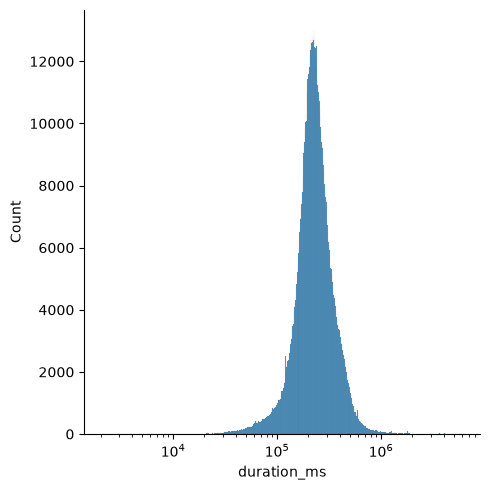

In [20]:
sns.displot(archivo['duration_ms'],log_scale=True);

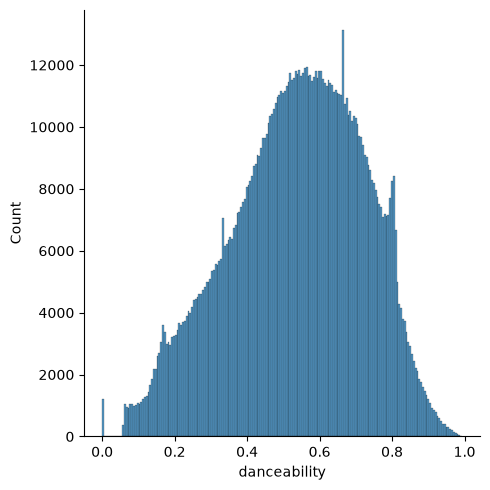

In [18]:
sns.displot(archivo['danceability'],log_scale=False);

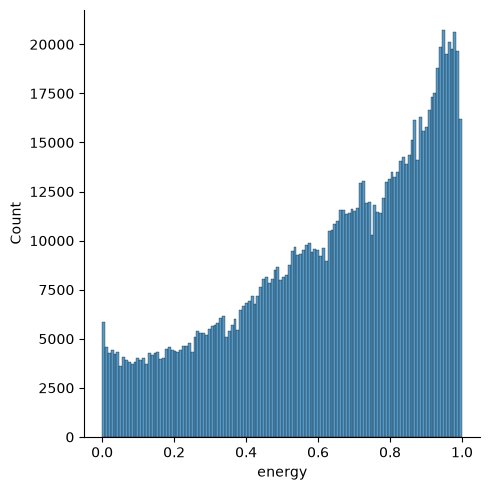

In [22]:
sns.displot(archivo['energy'],log_scale=False);

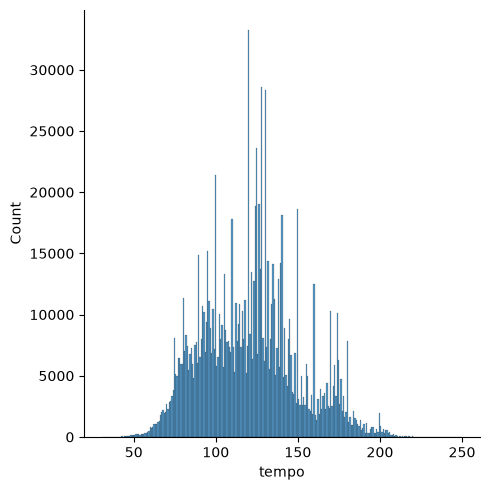

In [43]:
sns.displot(archivo['tempo'],log_scale=False);

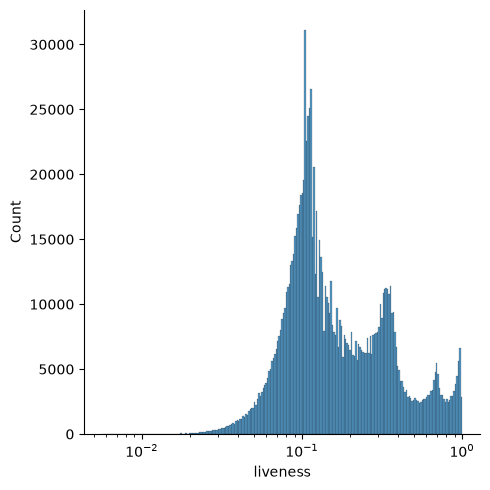

In [25]:
sns.displot(archivo['liveness'],log_scale=True);

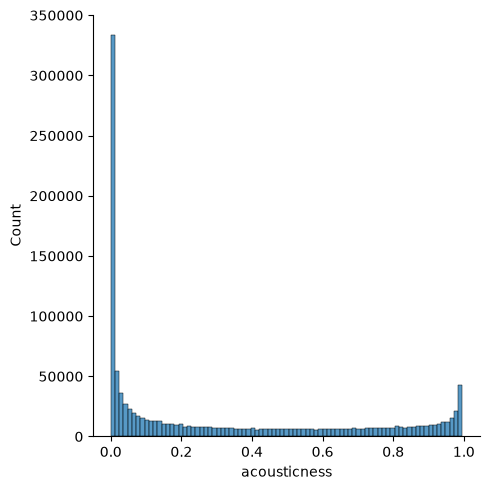

In [29]:
sns.displot(archivo['acousticness'],log_scale=False);

In [ ]:
#HABIAN TEMPOS A 0 COSA QUE NO ES POSIBLE
archivo['tempo']= archivo['tempo'].replace(0, np.nan)
medianas = archivo.groupby('genre')['tempo'].median()

archivo['tempo'] = archivo['tempo'].fillna(archivo['genre'].map(medianas))

In [ ]:
#EN EL CSV ORIGINAL HABIAN COMPASES A 0, NOES POSIBLE POR QUE ESO SIGNIFICA QUE ES MUSICA SIN METRICA
archivo['time_signature']= archivo['time_signature'].replace(0, np.nan)
modas = archivo.groupby('genre')['time_signature'].agg(
    lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan
)
archivo['time_signature'] = archivo['time_signature'].fillna(archivo['genre'].map(modas))

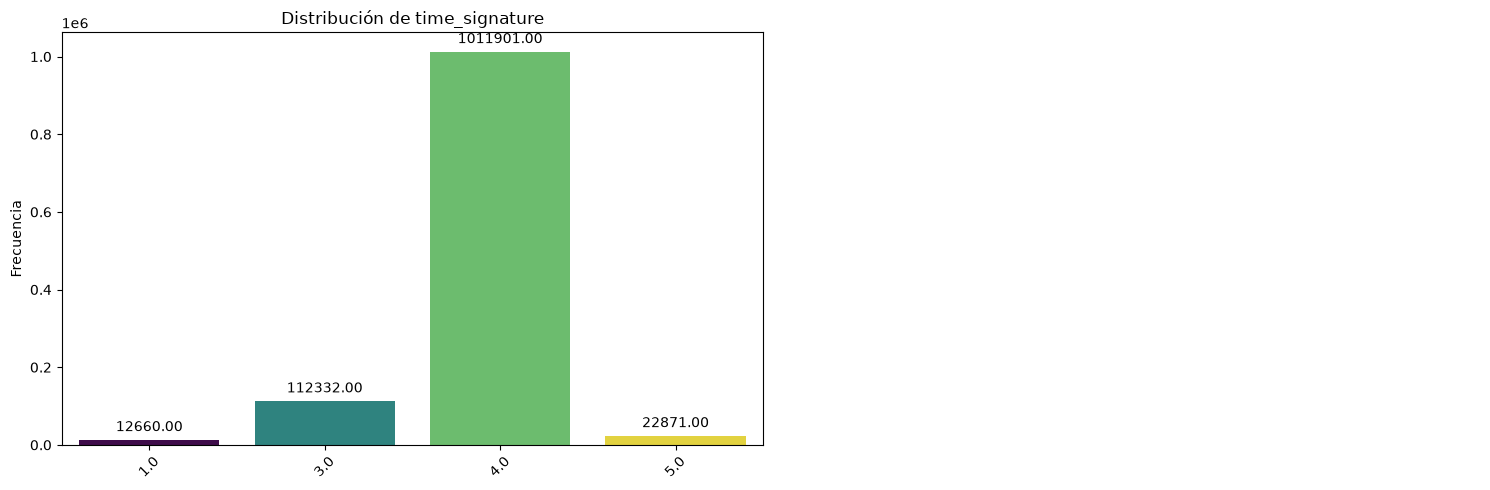

In [42]:
pinta_distribucion_categoricas(archivo,['time_signature'], mostrar_valores=True)

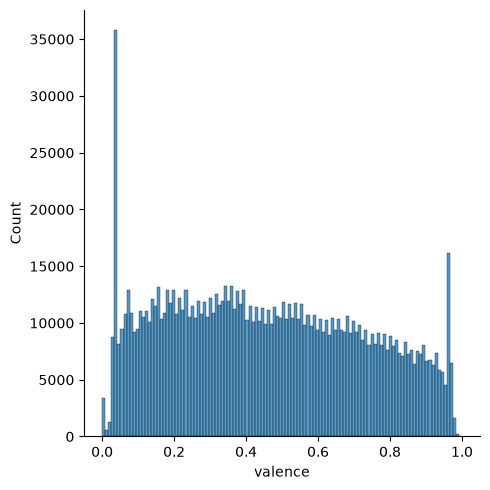

In [44]:
sns.displot(archivo.valence)

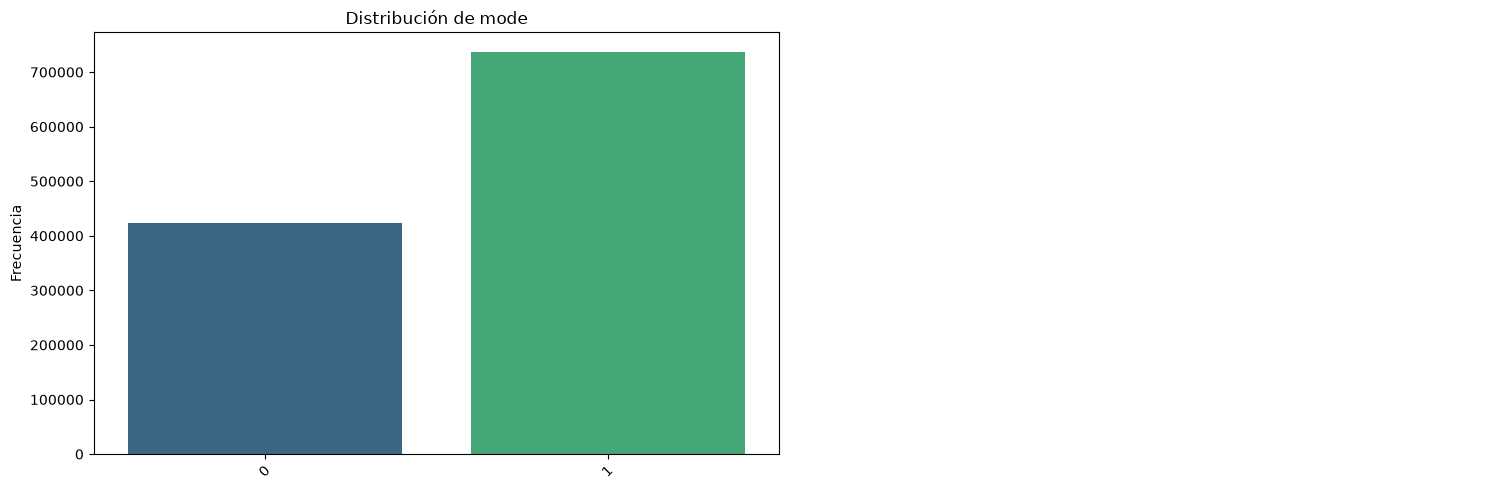

In [47]:
pinta_distribucion_categoricas(archivo, ['mode'])

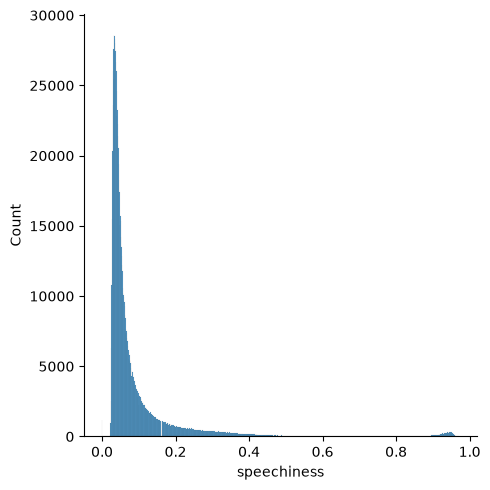

In [48]:
sns.displot(archivo.speechiness)

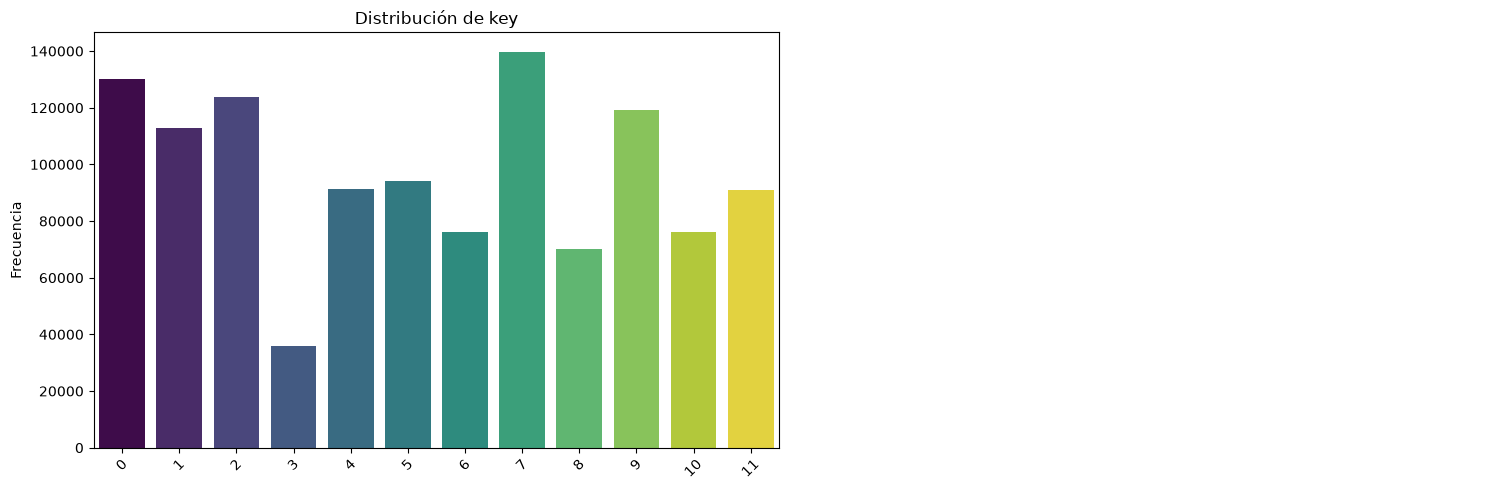

In [54]:
pinta_distribucion_categoricas(archivo, ['key'])

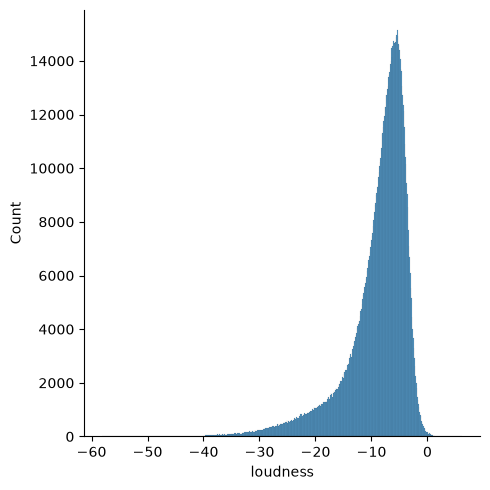

In [59]:
sns.displot(archivo.loudness, log_scale=False)

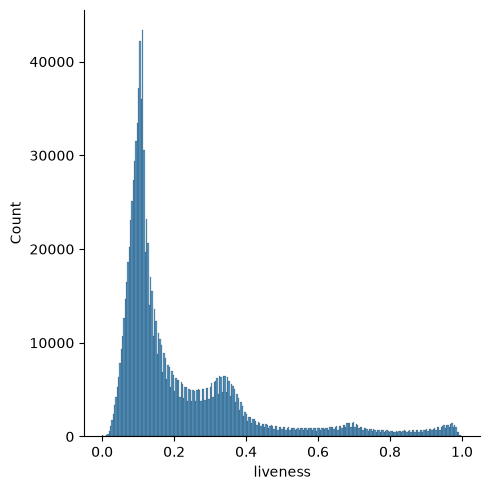

In [60]:
sns.displot(archivo.liveness)

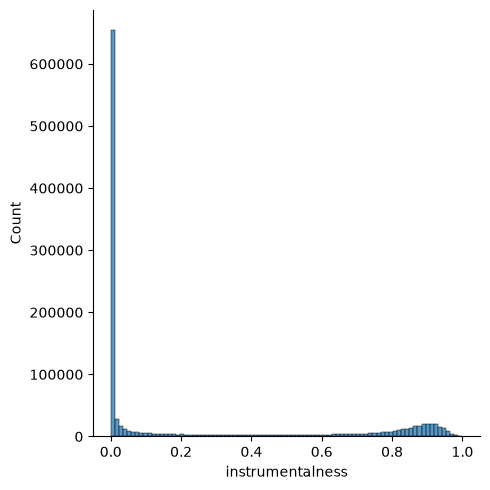

In [61]:
sns.displot(archivo.instrumentalness)

# DE AQUI PARA ABAJO COPIAR EN BIVARIABLE

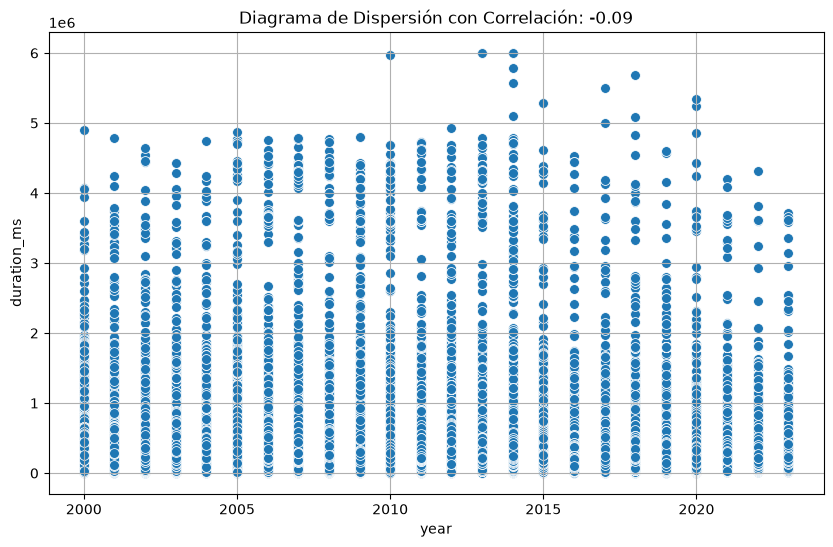

In [15]:
grafico_dispersion_con_correlacion(archivo,"year","duration_ms",mostrar_correlacion= True)

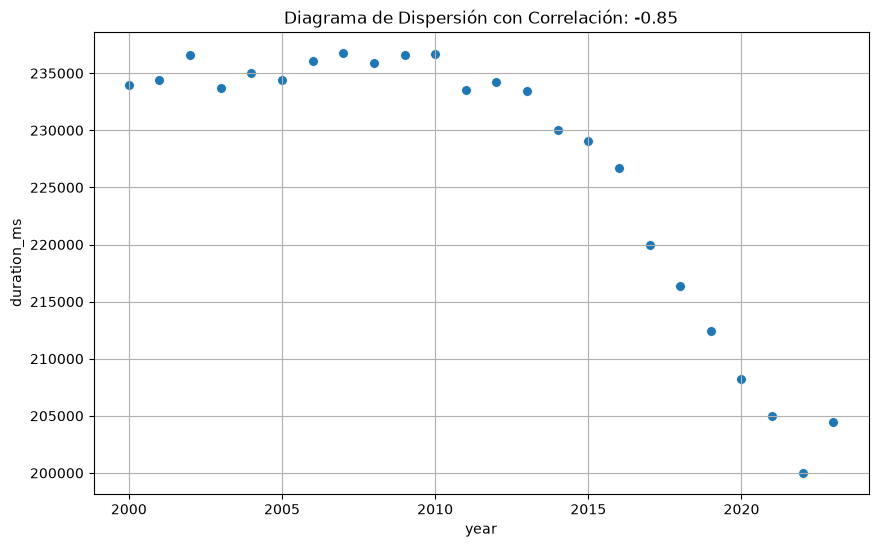

In [14]:
grafico_dispersion_con_correlacion(df1,"year","duration_ms",mostrar_correlacion= True)

In [ ]:
pearsonr(df1['year'],df1['duration_ms']) #rechazamos hipotesis nula

PearsonRResult(statistic=np.float64(-0.850585638512415), pvalue=np.float64(1.4064134509476118e-07))

In [ ]:
pearsonr(archivo['year'],archivo['duration_ms']) #rechazamos hipotesis nula PERO la correlacion entre ambas variables pasa a ser muy debil

PearsonRResult(statistic=np.float64(-0.09037138976606562), pvalue=np.float64(0.0))

speechiness
0.0000    1207965
0.0218     965347
0.0219      61118
0.0220     381448
0.0221     180273
           ...   
0.9670     732259
0.9680     792528
0.9690     792508
0.9700     792523
0.9710     414951
Name: tempo, Length: 1655, dtype: int64

artist_name                                              Alec Baldwin
track_name          Kapitel 19.4 - Meine fantastische Präsidentschaft
track_id                                       2mSMEkbV2iqjLHjoYEzC9X
popularity                                                          0
genre                                                      show-tunes
year                                                             2019
danceability                                                    0.622
energy                                                          0.233
key                                                                 0
loudness                                                      -19.507
mode                                                                1
speechiness                                                     0.971
acousticness                                                    0.281
instrumentalness                                                  0.0
liveness            